# 02 — Geometria de cobertura e métricas operacionais

**Objetivo.** Medir, a partir de trajetória GNSS + largura efetiva, a **área bruta**, a **área única** e a **sobreposição**, e calcular as métricas operacionais (distância, tempos por estado, ha/h, volume). Comparar tudo com a verdade analítica do simulador e mostrar **quando e quanto** a estimativa erra.

> ⚠️ **Dados SIMULADOS.** Os erros medidos aqui valem para este simulador (ruído RTK de ~2 cm, passadas retas). Não são a precisão do método em campo real.

**Ao final você deve conseguir verificar:** (1) uma conta feita à mão para 2 passadas bate com a função; (2) a sobreposição estimada fica perto da nominal (8,3%) no SIM-01; (3) a perda de GNSS reduz a cobertura estimada *sem* interpolação; (4) ruído de GNSS maior distorce a sobreposição.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from agrofleet.simulator.fleet import simulate
from agrofleet.analytics.frame import to_frame
from agrofleet.analytics.coverage import CoverageConfig, build_segments, swath_polygons, coverage
from agrofleet.analytics.metrics import machine_metrics
from agrofleet.geo import Projector
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
pts, truth = simulate(seed=7)
df = to_frame(pts)
FIELD = {"SIM-01": "TALHAO-A", "SIM-02": "TALHAO-B", "SIM-03": "TALHAO-C", "SIM-04": "TALHAO-D"}
print(len(df), "amostras SIMULADAS")

11331 amostras SIMULADAS


## 1. A definição de área, na prática

Para cada par de amostras consecutivas $P_i \to P_{i+1}$ em que **as duas** estão em `working`, têm posição, $\Delta t \le$ limite e largura informada, cria-se um retângulo de comprimento $\lVert P_{i+1}-P_i\rVert$ e largura $w_i$ (em UTC→UTM, metros). Então:

- **bruta** $=\sum_i \lVert P_{i+1}-P_i\rVert\, w_i$ — quanto a barra "varreu", contando repetições;
- **única** $= \text{área}\big(\bigcup_i R_i\big)$ — terra efetivamente coberta;
- **excesso** $=$ bruta $-$ única — área aplicada mais de uma vez;
- **região ≥2×** — área da união das interseções entre faixas *não vizinhas no tempo*.

**Por quê duas medidas de "sobreposição"?** Excesso soma *multiplicidade* (uma área coberta 3 vezes conta 2); a região ≥2× conta *onde*. A primeira é a que importa para custo de insumo; a segunda, para mapa.

**Por que exigir os dois extremos em `working`?** Descobrimos olhando o mapa: se só o ponto inicial fosse exigido, o primeiro passo *depois* do fim da passada (já em deslocamento, mas ainda herdando o estado anterior) virava uma faixa espúria de 24 m na cabeceira. A regra mais conservadora remove isso ao custo de perder meia amostra por passada (viés de subestimativa, medido abaixo).

**Alternativas.** (a) Buffer da polilinha com `shapely.buffer` (cantos arredondados/chanfrados nas curvas); (b) grade raster (conta cobertura por célula, resolve multiplicidade, perde precisão geométrica). Usamos retângulos por segmento: exatos em retas, simples de auditar.

**Verificação à mão.** Duas passadas paralelas de 495 m (1 Hz a 5 m/s perde o último passo), barra 24 m, espaçamento 22 m: bruta $=2\times495\times24=23\,760$ m²; sobreposição entre as faixas $=495\times(24-22)=990$ m².

bruta   :   23760.0 m²  (esperado 2*495*24 = 23760)
excesso :     980.0 m²  (esperado 495*2 = 990)
única   :   22780.0 m²  (esperado 22770)
região>=2x:   980.0 m²


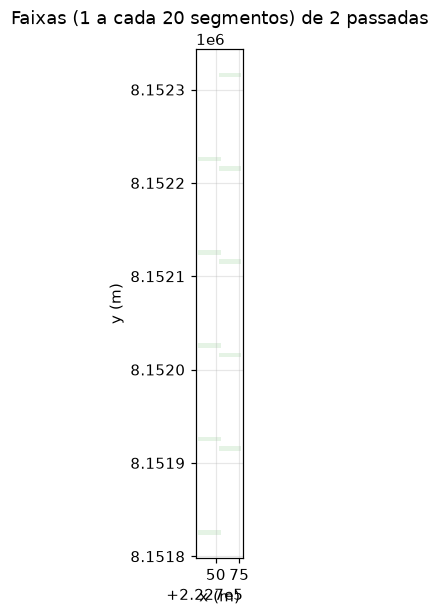

In [2]:
from datetime import timedelta
sys.path.insert(0, str(ROOT / "tests"))
from conftest import make_pts, T0
p1 = make_pts([(12, 0), (12, 500)])
p2 = make_pts([(34, 500), (34, 0)], t0=T0 + timedelta(seconds=1000))
mini = to_frame(p1 + p2)
seg = build_segments(mini, CoverageConfig())
r = coverage(mini, CoverageConfig())
print(f"bruta   : {r.gross_m2:9.1f} m²  (esperado 2*495*24 = {2*495*24})")
print(f"excesso : {r.excess_m2:9.1f} m²  (esperado 495*2 = {495*2})")
print(f"única   : {r.unique_m2:9.1f} m²  (esperado {2*495*24 - 495*2})")
print(f"região>=2x: {r.overlap_region_m2:7.1f} m²")
fig, ax = plt.subplots(figsize=(5, 6))
for poly in swath_polygons(seg)[::20]:
    x, y = poly.exterior.xy; ax.fill(x, y, alpha=.12, color="tab:green", lw=0)
ax.set_aspect("equal"); ax.set_title("Faixas (1 a cada 20 segmentos) de 2 passadas"); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
plt.show()

**Como ler a saída.** Bruta = 23 760 m², exatamente a conta à mão. Excesso = 980 m² (esperado 990, −1%) e única = 22 780 m² (esperado 22 770): a diferença de 10 m² tem causa conhecida — cada passada de 100 passos de 5 m tem pontos em y = 0…495 e 500…5, de modo que as duas só se sobrepõem em y ∈ [5, 495] = 490 m (490 × 2 = 980 m²), pois o último passo de cada uma não existe. Se os números *não* batessem, a função estaria errada — esse é o teste de sanidade mais barato e o primeiro a falhar quando alguém mexe na geometria. No gráfico, as duas passadas aparecem lado a lado com a faixa de 2 m de sobreposição no meio.

## 2. Estimado × verdade para as 4 máquinas

A verdade analítica vem do simulador: união exata dos retângulos planejados (sem ruído, sem perdas). Comparamos **bruta**, **única** e **% de sobreposição**.

In [3]:
rows = []
for m, f in FIELD.items():
    g = df[df.machine_id == m]
    s = coverage(g, field_lonlat=truth.fields[f], with_geojson=False).summary(); t = truth.areas[m]
    rows.append(dict(maquina=m, bruta_est=s["gross_ha"], bruta_real=t["planned_gross_ha"], unica_est=s["unique_ha"], unica_real=t["planned_unique_ha"],
                     sobrep_est_pct=s["overlap_pct_of_gross"], sobrep_real_pct=100*(1-t["planned_unique_ha"]/t["planned_gross_ha"]),
                     cobertura_talhao_pct=s["coverage_pct_of_field"], perda_pos=s["excluded_segments"]["no_position"]))
T = pd.DataFrame(rows).set_index("maquina")
T["erro_unica_pct"] = 100 * (T.unica_est / T.unica_real - 1)
T["erro_bruta_pct"] = 100 * (T.bruta_est / T.bruta_real - 1)
print(T.round(2).to_string())

         bruta_est  bruta_real  unica_est  unica_real  sobrep_est_pct  sobrep_real_pct  cobertura_talhao_pct  perda_pos  erro_unica_pct  erro_bruta_pct
maquina                                                                                                                                                
SIM-01       22.48        22.8      20.66       21.00            8.12             7.89                 98.36          0           -1.64           -1.39
SIM-02       21.29        21.6      20.38       20.75            4.28             3.94                 98.27          0           -1.77           -1.41
SIM-03       17.36        20.4      17.17       20.40            1.08             0.00                 83.86        241          -15.84          -14.92
SIM-04       22.48        22.8      20.66       21.00            8.12             7.89                 98.42          0           -1.64           -1.39


**Gráfico: estimado × verdade.** Barras lado a lado para a área única (ha) e a sobreposição (% da bruta). O que procurar: barras quase iguais nas máquinas sem perda de GNSS e uma diferença grande na SIM-03 (cobertura não interpolada sobre a perda de posição). Como verificar: os valores plotados são os da tabela acima (`T`); qualquer divergência visual deve aparecer também ali.

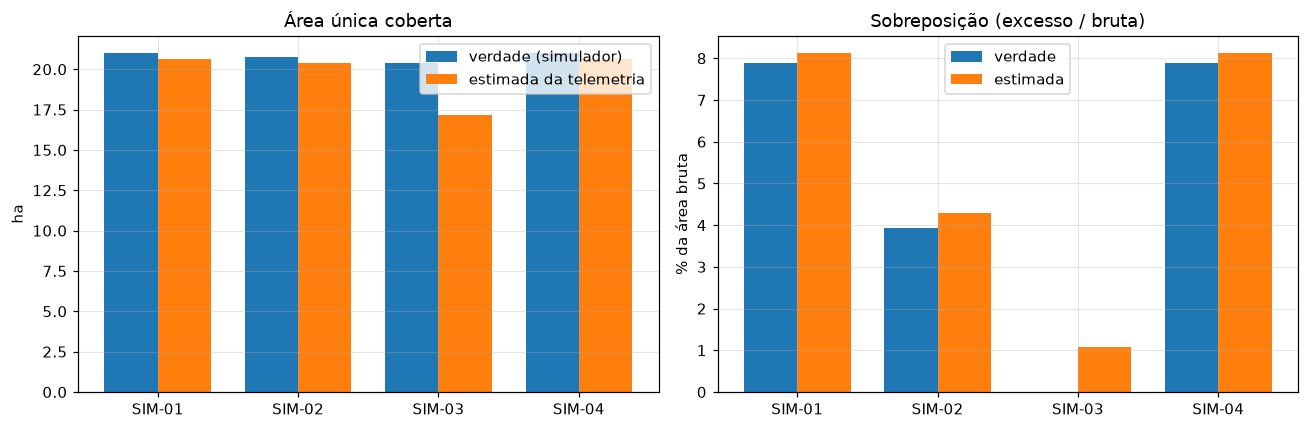

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(4); w = .38
ax[0].bar(x - w/2, T.unica_real, w, label="verdade (simulador)"); ax[0].bar(x + w/2, T.unica_est, w, label="estimada da telemetria")
ax[0].set_xticks(x, T.index); ax[0].set_ylabel("ha"); ax[0].set_title("Área única coberta"); ax[0].legend()
ax[1].bar(x - w/2, T.sobrep_real_pct, w, label="verdade"); ax[1].bar(x + w/2, T.sobrep_est_pct, w, label="estimada")
ax[1].set_xticks(x, T.index); ax[1].set_ylabel("% da área bruta"); ax[1].set_title("Sobreposição (excesso / bruta)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Como ler a tabela e o gráfico.**
- **SIM-01, 02, 04 (sem perda de GNSS):** `erro_unica_pct` e `erro_bruta_pct` são pequenos e **negativos** (subestimativa de ~1–2%). A causa **não foi isolada**; hipótese (não testada): a discretização a 1 Hz com a regra dos dois extremos perde parte das pontas das passadas. Não é ruído de posição (o RTK simulado tem 2 cm).
- A **sobreposição estimada** fica bem perto da verdade nas três máquinas: o erro é de décimos de ponto percentual. Para decisão de insumo, essa é a medida útil.
- **SIM-03:** a área única estimada é **muito menor** que a planejada e `perda_pos` é alto: são os segmentos sem posição. O sistema *não tem como saber* que a máquina cobriu aquela área. Reportar isso como "subestimativa por perda de GNSS" é o comportamento correto; interpolar linearmente "consertaria" o número, mas inventaria cobertura (e erraria nas curvas e paradas).
- `cobertura_talhao_pct` < 100% mesmo nas máquinas boas: a última passada do simulador ultrapassa o limite do talhão e há cabeceiras sem aplicação; a métrica mede o que a **telemetria** cobriu, não o que "deveria" ter sido coberto.

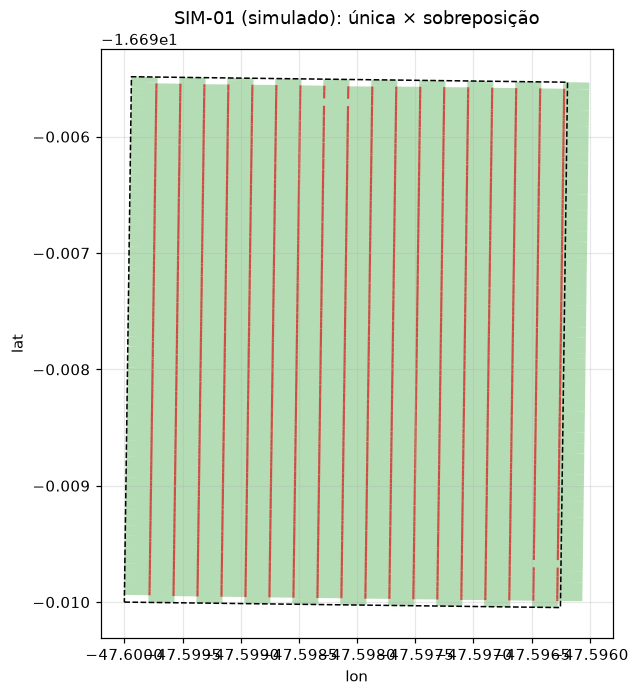

{'gross_ha': 22.483, 'unique_ha': 20.656, 'excess_ha': 1.826, 'overlap_region_ha': 1.72, 'overlap_pct_of_gross': 8.122, 'field_ha': 20.0, 'covered_in_field_ha': 19.671, 'uncovered_in_field_ha': 0.329, 'outside_field_ha': 0.985, 'coverage_pct_of_field': 98.355}


In [5]:
# Mapa de SIM-01: área única (verde), região coberta >=2x (vermelho) e limite do talhão
r = coverage(df[df.machine_id == "SIM-01"], field_lonlat=truth.fields["TALHAO-A"])
from shapely.geometry import shape
fig, ax = plt.subplots(figsize=(6, 7.5))
def draw(g, **kw):
    geoms = [g] if g.geom_type == "Polygon" else list(g.geoms)
    for p in geoms:
        x, y = p.exterior.xy; ax.fill(x, y, **kw)
draw(shape(r.union_geojson), color="tab:green", alpha=.35, lw=0)
if r.overlap_geojson: draw(shape(r.overlap_geojson), color="tab:red", alpha=.8, lw=0)
x, y = shape(truth.fields["TALHAO-A"]).exterior.xy; ax.plot(x, y, "k--", lw=1)
ax.set_aspect("equal"); ax.set_title("SIM-01 (simulado): única × sobreposição"); ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()
print({k: round(v, 3) for k, v in r.summary().items() if isinstance(v, float)})

**Como ler o mapa.** Faixas verdes contínuas; as linhas vermelhas finas entre elas são a região coberta duas vezes (2 m de barra repetida a cada passada, porque o espaçamento é 22 m para barra de 24 m). Na ponta superior e inferior as faixas ultrapassam o tracejado do talhão: é a parte `outside_field`. Isso é a **geometria da telemetria**, não um mapa de aplicação: nada aqui diz se o produto *realmente* caiu de forma uniforme (deriva, bicos, vento não são medidos).

## 3. Sensibilidades: o que muda a estimativa

Três perguntas que um engenheiro faz antes de confiar no número: **(a)** e se a largura efetiva informada estiver errada? **(b)** e se eu filtrar por precisão do receptor? **(c)** e se o GNSS tiver mais ruído (receptor sem RTK)?

**(a) Largura:** a área bruta e a única escalam linearmente com a largura; a *sobreposição* depende da razão largura/espaçamento — um erro de 5% na largura muda bastante a sobreposição estimada (2 m de 24 m = 8,3%; com 25,2 m passa a 3,1 m ≈ 12%).

In [6]:
g = df[df.machine_id == "SIM-01"]
res = []
for f in (0.90, 0.95, 1.00, 1.05, 1.10):
    gg = g.copy(); gg["working_width_m"] = gg.working_width_m * f
    s = coverage(gg, with_geojson=False).summary()
    res.append(dict(fator_largura=f, bruta_ha=s["gross_ha"], unica_ha=s["unique_ha"], sobrep_pct=s["overlap_pct_of_gross"]))
print(pd.DataFrame(res).round(2).to_string(index=False))

 fator_largura  bruta_ha  unica_ha  sobrep_pct
          0.90     20.23     20.15        0.43
          0.95     21.36     20.57        3.67
          1.00     22.48     20.66        8.12
          1.05     23.61     20.74       12.15
          1.10     24.73     20.82       15.82


**Como ler.** A área **bruta** escala com a largura (±10% → 20,2 a 24,7 ha), mas a **única** quase não muda (20,15 a 20,82 ha, ±2%): a terra coberta é essencialmente a mesma — o que muda é quantas vezes a barra repete. Por isso a **sobreposição** estimada é hipersensível: com a largura −5% cai de 8,1% para 3,7%; com +5% sobe para 12,2%; com −10% a barra (21,6 m) fica menor que o espaçamento (22 m) e a sobreposição some (0,4%, só ruído) — haveria fresta sem aplicação. Moral: *a largura efetiva tem de ser calibrada* (largura da barra com bicos ativos, sobreposição de jato, controle de seção). Se ela vier de um cadastro genérico, o número de sobreposição não é confiável mesmo com GNSS perfeito.

**(b) Filtro de precisão:** `max_accuracy_m` descarta segmentos cujo receptor reporta precisão pior que o limite. No SIM-03, a reconvergência RTK-float (0,35 m) entra ou sai conforme o limite.

In [7]:
g3 = df[df.machine_id == "SIM-03"]
res = []
for lim in (None, 5.0, 0.5, 0.1, 0.02):
    s = coverage(g3, CoverageConfig(max_accuracy_m=lim), with_geojson=False).summary()
    res.append(dict(max_accuracy_m=lim, unica_ha=s["unique_ha"], seg_descartados_precisao=s["excluded_segments"]["low_accuracy"], seg_sem_posicao=s["excluded_segments"]["no_position"]))
print(pd.DataFrame(res).round(2).to_string(index=False))

 max_accuracy_m  unica_ha  seg_descartados_precisao  seg_sem_posicao
            NaN     17.17                         0              241
           5.00     17.17                         0              241
           0.50     17.17                         0              241
           0.10     15.91                       114              241
           0.02     15.91                       114              241


**Como ler.** Limites frouxos (≥0,5 m) aceitam o trecho RTK-float; limites apertados (0,1 m ou menos) descartam esses segmentos e a área estimada cai. Não existe "limite certo": é um *trade-off* entre usar posições levemente piores (o erro lateral de 0,35 m numa barra de 24 m é ~1,5%) e perder cobertura. O que importa é que o descarte seja **contado e visível** (`seg_descartados_precisao`), não silencioso.

**(c) Ruído de posição:** injetamos ruído gaussiano adicional (σ em metros) nas posições do SIM-01 e re-estimamos a sobreposição. A verdade é ~7,9%.

 sigma_m  bruta_ha  unica_ha  sobrep_pct  regiao_2x_ha
     0.0     22.48     20.66        8.12          1.72
     0.1     22.49     20.36        9.49          1.60
     0.5     22.69     19.06       16.01          1.15
     1.0     23.41     18.15       22.44          0.87
     2.0     26.54     18.28       31.12          0.85
     3.0     31.42     18.77       40.26          1.24


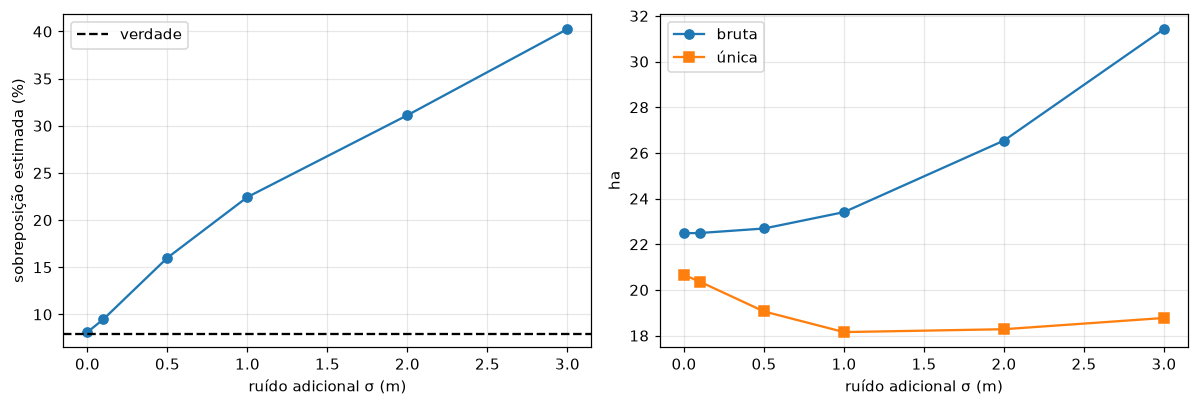

In [8]:
g = df[df.machine_id == "SIM-01"].dropna(subset=["lat"]).copy()
proj = Projector.for_points(g.lon, g.lat)
x, y = proj.fwd(g.lon, g.lat)
rng = np.random.default_rng(0)
res = []
for sigma in (0.0, 0.1, 0.5, 1.0, 2.0, 3.0):
    gg = g.copy()
    lon, lat = proj.inv(x + rng.normal(0, sigma, len(x)), y + rng.normal(0, sigma, len(x)))
    gg["lon"], gg["lat"] = lon, lat
    s = coverage(gg, CoverageConfig(max_accuracy_m=None), with_geojson=False).summary()
    res.append(dict(sigma_m=sigma, bruta_ha=s["gross_ha"], unica_ha=s["unique_ha"], sobrep_pct=s["overlap_pct_of_gross"], regiao_2x_ha=s["overlap_region_ha"]))
N = pd.DataFrame(res); print(N.round(2).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(N.sigma_m, N.sobrep_pct, "o-"); ax[0].axhline(100 * (1 - truth.areas["SIM-01"]["planned_unique_ha"] / truth.areas["SIM-01"]["planned_gross_ha"]), color="k", ls="--", label="verdade")
ax[0].set_xlabel("ruído adicional σ (m)"); ax[0].set_ylabel("sobreposição estimada (%)"); ax[0].legend()
ax[1].plot(N.sigma_m, N.bruta_ha, "o-", label="bruta"); ax[1].plot(N.sigma_m, N.unica_ha, "s-", label="única"); ax[1].set_xlabel("ruído adicional σ (m)"); ax[1].set_ylabel("ha"); ax[1].legend()
plt.tight_layout(); plt.show()

**Como ler.** O ruído **infla** a sobreposição: de 8,1% (σ=0) para 9,5% (σ=0,1 m), 16% (0,5 m), 22% (1 m) e 31% (2 m). O mecanismo é visível na coluna `bruta_ha`: como a área bruta é comprimento do caminho × largura e o comprimento é a soma de passos entre posições *ruidosas* a 1 Hz (passos de ~5 m), o jitter adiciona caminho que não existe (22,5 → 26,5 ha com σ=2 m). Ao mesmo tempo a área **única** *cai* (20,7 → ~18 ha), porque os retângulos de segmentos ligeiramente girados deixam frestas entre passadas. Resultado: bruta↑ e única↓ = excesso↑, sem que a máquina tenha sobreposto mais.

Implicações práticas: (1) com RTK (cm) os números são confiáveis; com GNSS de código (1–3 m) a **sobreposição estimada por esta geometria deixa de ser confiável** — com σ ≥ 1 m ela é dominada pelo ruído; (2) a região "coberta ≥2×" varia sem tendência clara com o ruído (1,7 → 0,85 → 1,24 ha): não use essa medida sem posição precisa; (3) mitigações (não implementadas aqui): suavizar a trajetória (Kalman/Savitzky–Golay), calcular o comprimento a partir da **velocidade reportada × Δt** em vez de diferença de posições, e usar a posição só para a união. Isso é uma limitação real do método atual.

Nota sobre o SIM-03 na tabela da seção 2: sua sobreposição estimada foi 1,08% embora a verdade seja 0% (espaçamento = largura). Veio do mesmo efeito — os 2 min de RTK-float (0,35 m) injetam jitter —, ou seja, um falso excesso de ~1 ponto percentual.

## 4. Métricas operacionais

**Contabilidade de tempo.** O intervalo $[t_i, t_{i+1}]$ vai para o estado da amostra $i$ se $\Delta t \le$ limite; senão o intervalo inteiro vai para `no_data` (não sabemos o que aconteceu). **Distância** soma só trechos com posição nos dois extremos e $\Delta t \le$ limite, descartando saltos (> 25 m/s implícitos); o trecho reto sobre lacuna é reportado à parte (`distance_across_gaps`).

**Produtividade.** `unique_ha_per_working_h` (capacidade de campo efetiva em trabalho) e `unique_ha_per_engaged_h` (inclui deslocamento, reabastecimento, parada). Usamos a área **única**, não a bruta: contar sobreposição como produtividade inflaria o ha/h.

**Volume.** Duas fontes independentes: integral da vazão no tempo e delta do contador acumulado. Quando existem as duas, a discrepância é um teste de consistência dos sensores.

In [9]:
rows = []
for m, g in df.groupby("machine_id"):
    r = machine_metrics(g)
    th = r["time_h"]
    rows.append(dict(maquina=m, span_h=r["span_h"], trabalho_h=th["working"], desloc_h=th["transport"], reabast_h=th["refilling"], falha_h=th["fault"], sem_dado_h=th["no_data"],
                     soma_h=sum(th.values()), dist_km=r["distance_km"], dist_lacuna_km=r["distance_across_gaps_km_straight_line"],
                     vol_vazao_L=r["volume_from_flow_l"], vol_contador_L=r["volume_from_counter_l"], discrep_vol_pct=r["volume_source_discrepancy_pct"],
                     taxa_realizada_Lha=r["realized_rate_lha_on_unique_area"], ha_h_trabalho=r["productivity"]["unique_ha_per_working_h"],
                     ha_h_engajado=r["productivity"]["unique_ha_per_engaged_h"]))
M = pd.DataFrame(rows).set_index("maquina"); print(M.round(3).T.to_string())

maquina               SIM-01    SIM-02    SIM-03    SIM-04
span_h                 0.730     0.899     0.652     0.866
trabalho_h             0.524     0.497     0.468     0.522
desloc_h               0.106     0.186     0.135     0.243
reabast_h              0.100     0.100     0.050     0.100
falha_h                0.000     0.117     0.000     0.000
sem_dado_h             0.000     0.000     0.000     0.000
soma_h                 0.730     0.899     0.652     0.866
dist_km               12.096    13.792    10.683    15.801
dist_lacuna_km         0.000     0.000     0.176     0.000
vol_vazao_L         2291.998  2168.000  1874.394  2172.348
vol_contador_L      2293.193  2169.356  2051.660  2173.665
discrep_vol_pct       -0.052    -0.062    -8.640    -0.061
taxa_realizada_Lha   110.958   106.365   109.175   105.165
ha_h_trabalho         39.429    41.039    36.725    39.534
ha_h_engajado         28.307    22.675    26.323    23.865


**Como ler.**
- **Contabilidade fecha:** `soma_h` = `span_h` em todas as máquinas — todo segundo foi atribuído a algum estado (ou a `no_data`). `falha_h` do SIM-02 = 0,117 h = 7 min, exatamente a parada injetada.
- **Duas fontes de volume concordam** em SIM-01/02/04 (discrepância ≈ −0,05%), e **discordam em −8,6% no SIM-03**: é a assinatura dos 2,5 min em que vazão e pressão vieram `None` (≈ 150 s × 71 L/min ≈ 177 L, a diferença observada entre contador e integral). A integral da vazão só soma onde há dado — não "completa". Esse tipo de discrepância é um bom *detector* de sensor faltando.
- **`taxa_realizada_Lha` > 100:** volume ÷ **área única** dá 105–111 L/ha para uma taxa nominal de 100. O excedente é a sobreposição (SIM-01: +8% de área repetida ≈ +11 L/ha). Não é erro de vazão; é dose média efetiva maior que a nominal onde há repasse. No SIM-03 o número mistura dois vieses (volume incompleto no numerador, área incompleta no denominador) e não deve ser lido isoladamente.
- **ha/h:** ~37–41 ha/h em trabalho e ~23–28 ha/h considerando todo o tempo engajado (deslocamento, abastecimento, parada). O SIM-03 tem ha/h menor porque a área sob perda de GNSS não conta.
- **`dist_lacuna_km`:** é a distância em linha reta nos trechos **não medidos** (perda de posição ou lacuna de tempo). No SIM-03 vale 0,176 km (a máquina andou durante a perda de GNSS); nas demais é 0. Ela **não** entra em `dist_km`, mas as duas partes fecham o percurso: 10,683 + 0,176 = 10,859 km contra 10,852 km da geodésica completa.

## 5. Verificação independente com PostGIS (geodésia)

O cálculo em Python usa **UTM** (plano). O PostGIS calcula comprimento e área em **`geography`** (elipsoide WGS84). São métodos independentes entre si; se concordarem, descartamos erro de projeção. O script `scripts/validate_geodesy.py` roda isso contra o PostGIS real da pilha (Podman) e grava `experiments/geodesy_check.json`; abaixo só lemos o resultado.

In [10]:
gj = ROOT / "experiments" / "geodesy_check.json"
if gj.exists():
    G = json.loads(gj.read_text())
    rows = []
    for m, v in G["machines"].items():
        rows.append(dict(maquina=m, trilha_postgis_m=v["track_length_m"]["postgis_geography"], trilha_pyproj_geod_m=v["track_length_m"]["pyproj_geod"],
                         trilha_utm_metrics_m=v["track_length_m"]["python_utm_metrics_distance_km_x1000"], area_talhao_postgis_m2=v["field_area_m2"]["postgis_geography"],
                         area_talhao_utm_m2=v["field_area_m2"]["python_utm"], dif_area_utm_vs_geography_pct=100 * v["rel_diff_area_utm_vs_geography"],
                         pontos_dentro_talhao=v["points_within_field_postgis_st_within"]))
    print("banco:", G["db"], "| origem:", G["origin"]); print(pd.DataFrame(rows).set_index("maquina").round(2).T.to_string())
else:
    print("experiments/geodesy_check.json ausente: rode a pilha (docker/podman compose up) e scripts/validate_geodesy.py")

banco: postgresql | origem: simulated
maquina                           SIM-01     SIM-02     SIM-03     SIM-04
trilha_postgis_m                12089.70   13784.19   10852.50   15792.47
trilha_pyproj_geod_m            12089.70   13784.19   10852.50   15792.47
trilha_utm_metrics_m            12096.34   13791.73   10682.79   15801.11
area_talhao_postgis_m2         199780.43  199781.80  199780.43  199781.80
area_talhao_utm_m2             200000.00  200000.00  200000.00  200000.00
dif_area_utm_vs_geography_pct       0.11       0.11       0.11       0.11
pontos_dentro_talhao             1990.00    2293.00    1615.00    1984.00


**Como ler.**
- `trilha_postgis_m` e `trilha_pyproj_geod_m` coincidem até o centímetro: PostGIS (`geography`) e `pyproj.Geod` calculam a geodésica no elipsoide WGS84. (Atenção: ambos usam algoritmo equivalente, então concordar entre si é esperado; o que importa é que ambos são **independentes da projeção UTM** que usamos nas contas.)
- `trilha_utm_metrics_m` (nossa distância, em UTM, com saltos e lacunas excluídos por definição) fica ~0,05% acima da geodésica nas três máquinas sem perda de GNSS — compatível com o fator de escala do UTM neste local. No SIM-03 ela fica ~1,6% abaixo porque a distância sob perda de GNSS não entra em `dist_km` (o PostGIS aqui liga a última e a próxima posição por uma reta); somando `dist_lacuna_km` (seção 4) o total volta a bater.
- **Área do talhão:** UTM dá 200 000 m² (o simulador define o talhão em metros planos), o PostGIS `geography` dá 199 780 m²: UTM **superestima 0,11%** neste local (~2,6° do meridiano central do fuso; fator de escala k≈1,0005 → área × k² ≈ 1,0011). Para talhões de dezenas de hectares isso é desprezível frente às outras incertezas (largura, ruído), mas é bom saber que a conta em UTM não é exata.
- `pontos_dentro_talhao` é o `ST_Within` com índice GIST: por exemplo, SIM-01 tem 1990 de 2628 amostras dentro do talhão A — o restante é depósito, deslocamento e cabeceiras.

## Resumo
- Geometria: retângulos por segmento, união exata, excesso e região ≥2× — conferidos à mão e contra o simulador.
- A estimativa **subestima** levemente (viés de borda de passada) e **falha de forma visível** onde não há posição.
- Sobreposição depende de largura efetiva calibrada e de ruído de posição; sem RTK os números pioram.
- **Próximo:** notebook 03 — séries temporais, anomalias (regras × IsolationForest) e ROI com sensibilidade.